# 01 — Exploration et préparation des données

Ce notebook permet d'explorer le jeu de données automobile, de vérifier sa qualité et de préparer les données pour l'entraînement des modèles de régression.

In [313]:
import pandas as pd
import matplotlib.pyplot as plt

# Fusion des deux fichiers raw
df_1 = pd.read_csv(
    "../data/raw/vehicles.csv",
    encoding="latin-1"
)

df_2 = pd.read_csv(
    "../data/raw/vehicles_2.csv",
    encoding="latin-1"
)

df_merged = pd.concat(
    [df_1, df_2],
    ignore_index=True
).drop_duplicates()
df_merged["LASTMODDATE"] = pd.to_datetime(
    df_merged["LASTMODDATE"],
    errors="coerce"
)

df_merged = (
    df_merged
    .sort_values("LASTMODDATE")
    .drop_duplicates(
        subset="ID",
        keep="last"
    )
)
df_merged.to_csv(
    "../data/raw/vehicles.csv",
    index=False,
    encoding="latin-1"
)

print("Nombre de lignes après fusion :", len(df_merged))


# Chargement normal pour la suite du notebook
df = pd.read_csv(
    "../data/raw/vehicles.csv",
    encoding="latin-1"
)

df.head()

Nombre de lignes après fusion : 1660


,FINANCING_MONTHS,FINANCING_CASHDOWN,FINANCING_MONTHLYPAYMENT,FINANCING_INTEREST,FINANCING_FINANCINGCOST,FINANCING_TOTALOBLIGATION,LEASING_MONTHS,LEASING_CASHDOWN,LEASING_MONTHLYPAYMENT,LEASING_RESIDUALVALUE,...,CERTIFICATION,CERTIFIED,"TRIM,en",OEMID,Video,basePrice,BasePricePlusFee,MSRPPricePlusFee,DeliveryStatus,AS_IS
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,Preferred AWD Bluetooth Mags,NaN,NaN,20995,20995,20995.0,delivered,0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,Preferred ST AWD Leather/Cloth Mags Apple Car...,NaN,NaN,27995,27995,27995.0,delivered,0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,S Screen Bluetooth Camera A/C Electric Group,NaN,NaN,16495,16495,17495.0,delivered,0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,SL PLUS 62kWh Leather GPS Large Battery,NaN,NaN,19495,19495,19995.0,delivered,0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,False,Comfortline 4Motion Alloy Wheels Leather Panor...,NaN,NaN,23495,23495,24995.0,delivered,0


In [314]:
df.shape

(1660, 106)

In [315]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1660 entries, 0 to 1659
Columns: 106 entries, FINANCING_MONTHS to AS_IS
dtypes: bool(1), float64(40), int64(16), object(49)
memory usage: 1.3+ MB


## Sélection des variables

Le jeu de données contient 106 variables. Comme l'objectif du projet est de prédire le prix d'un véhicule, seules les variables pertinentes pour cette prédiction seront conservées avant le nettoyage des données.

In [316]:
df.columns.tolist()

['FINANCING_MONTHS',
 'FINANCING_CASHDOWN',
 'FINANCING_MONTHLYPAYMENT',
 'FINANCING_INTEREST',
 'FINANCING_FINANCINGCOST',
 'FINANCING_TOTALOBLIGATION',
 'LEASING_MONTHS',
 'LEASING_CASHDOWN',
 'LEASING_MONTHLYPAYMENT',
 'LEASING_RESIDUALVALUE',
 'LEASING_TOTALOBLIGATION',
 'LEASING_KMPERYEAR',
 'LEASING_COSTPERKM',
 'NOTEE',
 'NOTEF',
 'DEALERNAME',
 'BODYDESCE',
 'BODYDESCF',
 'BODYDOORS',
 'BODYSTYLE',
 'BODYSTYLE,en',
 'CATEGORY',
 'CATEGORY,en',
 'COLORE',
 'COLORF',
 'COSTPRICE',
 'CUBICCAPACITY',
 'DRIVETRAIN',
 'DRIVETRAIN,en',
 'ENGINEDESCE',
 'ENGINEDESCF',
 'ENGINETYPE',
 'ENTRYDATE',
 'FUEL',
 'FUEL,en',
 'ID',
 'INDUCTION',
 'INDUCTION,en',
 'INTCOLORE',
 'INTCOLORF',
 'KM',
 'LASTMODDATE',
 'LISTPRICE',
 'MAKE',
 'MODEL',
 'MULTI_PHOTO',
 'NOTEEXTRAE',
 'NOTEEXTRAF',
 'ODOMETER',
 'PASSENGERS',
 'PHOTO',
 'PRICE',
 'REPAIRS1',
 'REPAIRS2',
 'SERIALNUMBER',
 'SERVICEDATE',
 'SOLDDATE',
 'STOCKNUMBER',
 'TRANSDESCE',
 'TRANSDESCF',
 'TRANSGEARS',
 'TRANSTYPE',
 'TRANSTYPE,

## Sélection des variables

Le jeu de données contient 106 variables. Pour ce premier TP, seules les variables pertinentes pour estimer le prix d'un véhicule sont conservées.

La variable cible est `PRICE`.

Les variables directement liées au prix, les identifiants, les URL, les textes libres et les variables administratives sont exclues afin de simplifier le modèle et d'éviter les fuites de données.

In [317]:
variables_numeriques = [
    "YEAR",
    "KM",
    "BODYDOORS",
    "PASSENGERS"
]

variables_categorielles = [
    "MAKE",
    "MODEL",
    "BODYDESCF",
    "DRIVETRAIN",
    "FUEL",
    "TRANSDESCF",
    "COLORF"
]

cible = "PRICE"

In [318]:
colonnes_retenues = variables_numeriques + variables_categorielles + [cible]

df_model = df[colonnes_retenues].copy()

df_model.shape

(1660, 12)

In [319]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1660 entries, 0 to 1659
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   YEAR        1660 non-null   int64 
 1   KM          1660 non-null   int64 
 2   BODYDOORS   1660 non-null   int64 
 3   PASSENGERS  1660 non-null   int64 
 4   MAKE        1660 non-null   object
 5   MODEL       1660 non-null   object
 6   BODYDESCF   1660 non-null   object
 7   DRIVETRAIN  1659 non-null   object
 8   FUEL        1650 non-null   object
 9   TRANSDESCF  1660 non-null   object
 10  COLORF      1660 non-null   object
 11  PRICE       1660 non-null   int64 
dtypes: int64(5), object(7)
memory usage: 155.8+ KB


In [320]:
df_model.isnull().sum()

YEAR           0
KM             0
BODYDOORS      0
PASSENGERS     0
MAKE           0
MODEL          0
BODYDESCF      0
DRIVETRAIN     1
FUEL          10
TRANSDESCF     0
COLORF         0
PRICE          0
dtype: int64

In [321]:
df_model[
    df_model["DRIVETRAIN"].isna()
    | df_model["FUEL"].isna()
][
    ["YEAR", "MAKE", "MODEL", "DRIVETRAIN", "FUEL", "PRICE"]
]

,YEAR,MAKE,MODEL,DRIVETRAIN,FUEL,PRICE
31,2023,Chrysler,Pacifica Hybrid,Autre,NaN,37995
85,2021,Jeep,Wrangler 4xe,4 roues motrices,NaN,32995
118,2021,Jeep,Wrangler 4xe,4 roues motrices,NaN,33995
161,2020,Honda,Clarity Plug-in Hybrid,Autre,NaN,22995
163,2026,GMC,Sierra 2500 HD,NaN,NaN,119900
189,2021,Ford,Escape,Autre,NaN,19995
260,2021,Jeep,Wrangler 4xe,4 roues motrices,NaN,36995
368,2022,Ford,F-150,4 roues motrices,NaN,40995
529,2022,Ford,Escape,4 roues motrices,NaN,20495
535,2018,Mitsubishi,Outlander PHEV,4 roues motrices,NaN,16995


### Traitement des valeurs manquantes catégorielles

Quelques valeurs sont manquantes dans les variables `FUEL` et `DRIVETRAIN`.

Comme ces variables sont catégorielles et que les véhicules concernés peuvent apporter une information utile au modèle, les observations sont conservées.

Les valeurs manquantes sont remplacées par la catégorie `Inconnu` afin d'éviter d'attribuer arbitrairement une catégorie existante.

In [322]:
df_model["FUEL"] = df_model["FUEL"].fillna("Inconnu")
df_model["DRIVETRAIN"] = df_model["DRIVETRAIN"].fillna("Inconnu")

In [323]:
df_model.isnull().sum()

YEAR          0
KM            0
BODYDOORS     0
PASSENGERS    0
MAKE          0
MODEL         0
BODYDESCF     0
DRIVETRAIN    0
FUEL          0
TRANSDESCF    0
COLORF        0
PRICE         0
dtype: int64

In [324]:
df_model.duplicated().sum()

np.int64(0)

In [325]:
df_model.describe()

,YEAR,KM,BODYDOORS,PASSENGERS,PRICE
count,1660.000000,1660.000000,1660.000000,1660.000000,1660.000000
mean,2021.463253,70568.927108,4.226506,5.147590,23455.788554
std,2.238191,27826.749661,0.569907,0.713615,8088.072083
min,2007.000000,4192.000000,0.000000,0.000000,6995.000000
25%,2020.000000,51076.250000,4.000000,5.000000,17995.000000
50%,2022.000000,69633.000000,4.000000,5.000000,21995.000000
75%,2023.000000,91055.750000,5.000000,5.000000,27495.000000
max,2026.000000,262533.000000,5.000000,8.000000,119900.000000


In [326]:
df_model[
    (df_model["BODYDOORS"] == 0)
    | (df_model["KM"] == df_model["KM"].max())
    | (df_model["PRICE"] == df_model["PRICE"].max())
][
    [
        "YEAR",
        "MAKE",
        "MODEL",
        "BODYDESCF",
        "BODYDOORS",
        "PASSENGERS",
        "KM",
        "PRICE"
    ]
]

,YEAR,MAKE,MODEL,BODYDESCF,BODYDOORS,PASSENGERS,KM,PRICE
26,2019,Ford,F-150,Camion,4,5,262533,16995
150,2023,GMC,Savana Cargo,Fourgonnette,0,0,62366,32995
163,2026,GMC,Sierra 2500 HD,Berline,0,0,7500,119900
741,2023,MINI,Cooper EV,Coupé,0,4,56983,21495
1162,2020,Ford,Transit Cargo Van,Minifourgonnette,0,2,16145,32995


### Traitement de BODYDOORS = 0

Quatre véhicules présentent une valeur `BODYDOORS` égale à 0.

Cette valeur ne correspond pas à un nombre réel de portes et est considérée comme une valeur manquante ou incorrectement codée.

Comme seulement quatre observations sont concernées, elles sont conservées et la valeur 0 est remplacée par la médiane de `BODYDOORS`.

In [327]:
median_bodydoors = df_model.loc[
    df_model["BODYDOORS"] > 0,
    "BODYDOORS"
].median()

df_model.loc[
    df_model["BODYDOORS"] == 0,
    "BODYDOORS"
] = median_bodydoors

print("Médiane utilisée :", median_bodydoors)
print("Valeurs BODYDOORS = 0 restantes :", (df_model["BODYDOORS"] == 0).sum())

Médiane utilisée : 4.0
Valeurs BODYDOORS = 0 restantes : 0


### Distribution du prix des véhicules

La distribution de la variable cible `PRICE` permet d'observer la répartition des prix dans le jeu de données et d'identifier visuellement une éventuelle asymétrie ou la présence de valeurs extrêmes.

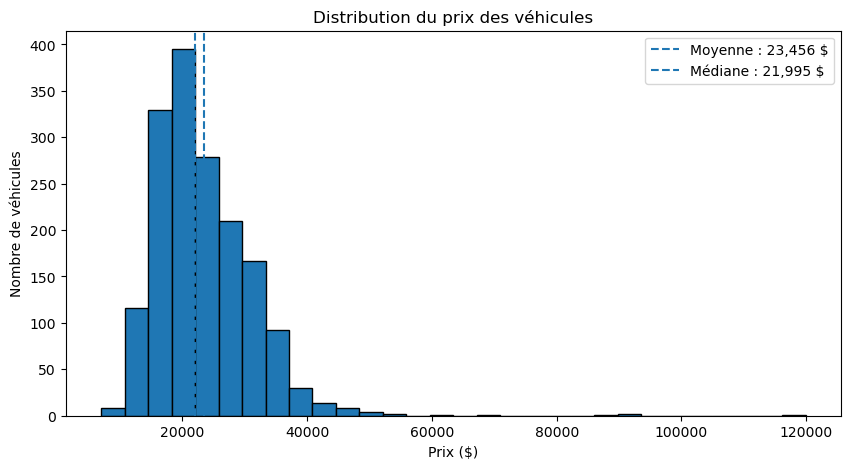

In [328]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_model["PRICE"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    df_model["PRICE"].mean(),
    linestyle="--",
    label=f"Moyenne : {df_model['PRICE'].mean():,.0f} $"
)

plt.axvline(
    df_model["PRICE"].median(),
    linestyle="--",
    label=f"Médiane : {df_model['PRICE'].median():,.0f} $"
)

plt.title("Distribution du prix des véhicules")
plt.xlabel("Prix ($)")
plt.ylabel("Nombre de véhicules")
plt.legend()

plt.show()

In [329]:
df_model["PASSENGERS"].value_counts().sort_index()

PASSENGERS
0       4
2       9
3       1
4      52
5    1381
6      96
7     101
8      16
Name: count, dtype: int64

### Interprétation de la distribution du prix

La majorité des véhicules se concentre dans une plage de prix comprise approximativement entre 15 000 $ et 35 000 $.

La distribution présente une asymétrie vers les prix élevés. La moyenne du prix est d'environ 23 456 $ tandis que la médiane est de 21 995 $.

Cet écart s'explique par la présence de quelques véhicules beaucoup plus chers que la majorité du jeu de données avec des prix pouvant dépasser 60 000 $ et atteindre environ 120 000 $.

Ces observations sont conservées puisqu'elles correspondent à des véhicules réels et peuvent apporter de l'information utile lors de l'entraînement et de l'évaluation des modèles.

### Relation entre l'année du véhicule et son prix

On analyse maintenant la relation entre l'année du véhicule (`YEAR`) et la variable cible `PRICE`.

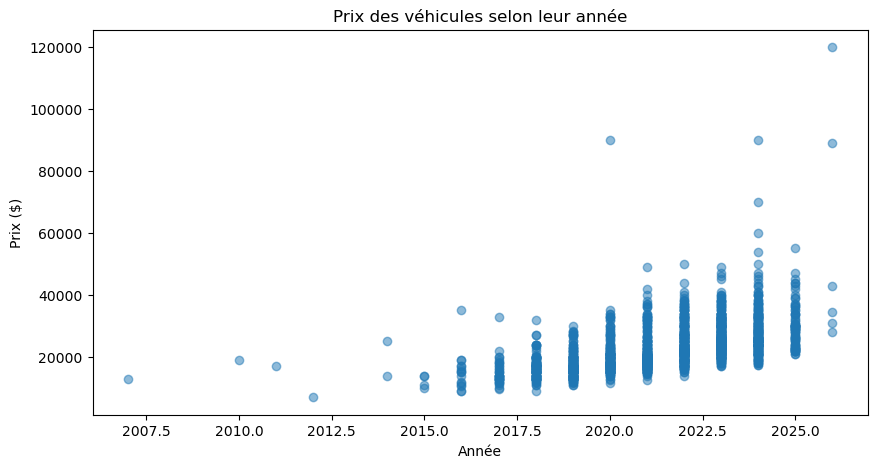

In [346]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df_model["YEAR"],
    df_model["PRICE"],
    alpha=0.5
)

plt.title("Prix des véhicules selon leur année")
plt.xlabel("Année")
plt.ylabel("Prix ($)")

plt.show()

### Interprétation de la relation entre l'année et le prix

Le graphique montre une tendance générale à la hausse du prix lorsque l'année du véhicule est plus récente.

La relation est assez nette, mais elle n'est pas parfaitement linéaire. Pour une même année, les prix peuvent varier fortement, particulièrement parmi les véhicules récents.

Cela indique que `YEAR` constitue une variable importante pour prédire le prix, mais qu'elle doit être combinée avec d'autres caractéristiques comme le kilométrage, la marque, le modèle et le type de véhicule.

Quelques véhicules récents présentent des prix nettement supérieurs au reste du jeu de données. Ces observations sont conservées puisqu'elles correspondent à des véhicules réels.

### Relation entre le kilométrage et le prix

On analyse maintenant la relation entre le kilométrage (`KM`) et la variable cible `PRICE`.

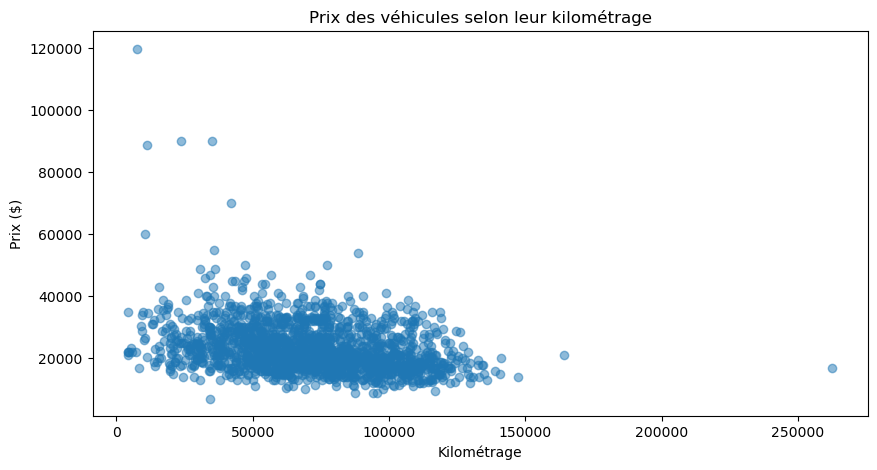

In [347]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df_model["KM"],
    df_model["PRICE"],
    alpha=0.5
)

plt.title("Prix des véhicules selon leur kilométrage")
plt.xlabel("Kilométrage")
plt.ylabel("Prix ($)")

plt.show()

### Interprétation de la relation entre le kilométrage et le prix

Le graphique montre une tendance générale à la baisse du prix lorsque le kilométrage augmente.

Les véhicules ayant un faible kilométrage présentent une grande variété de prix, incluant les véhicules les plus chers du jeu de données. À mesure que le kilométrage augmente, les prix ont tendance à se concentrer vers des valeurs plus faibles.

La relation reste toutefois dispersée, ce qui indique que le kilométrage est une variable pertinente pour la prédiction, mais qu'il doit être combiné avec d'autres caractéristiques du véhicule.

Le véhicule présentant plus de 260 000 km est conservé puisqu'il correspond à une observation réelle et que son prix demeure plausible.

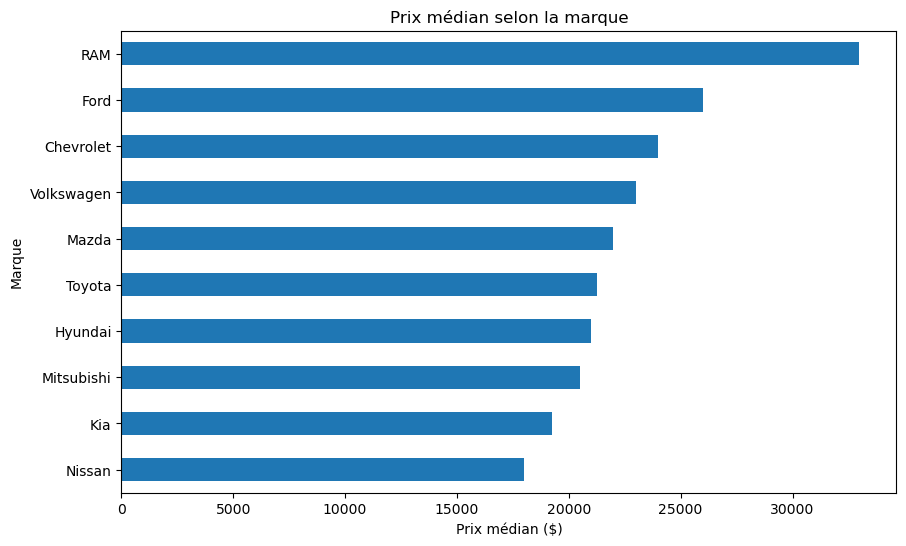

In [348]:
top_marques = (
    df_model["MAKE"]
    .value_counts()
    .head(10)
    .index
)

prix_median_marque = (
    df_model[df_model["MAKE"].isin(top_marques)]
    .groupby("MAKE")["PRICE"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 6))

prix_median_marque.plot(kind="barh")

plt.title("Prix médian selon la marque")
plt.xlabel("Prix médian ($)")
plt.ylabel("Marque")

plt.show()

### Interprétation du prix selon la marque

Les prix médians diffèrent sensiblement entre les marques les plus représentées dans le jeu de données.

Cela indique que la marque peut apporter une information pertinente pour prédire le prix d'un véhicule.

Ces écarts doivent toutefois être interprétés avec prudence, puisqu'ils peuvent également être influencés par d'autres caractéristiques comme l'année, le kilométrage, le modèle ou le type de véhicule.

### Prix selon le type de carrosserie

Le type de carrosserie (`BODYDESCF`) peut également influencer le prix d'un véhicule.

On compare ici le prix médian pour chaque type de carrosserie présent dans le jeu de données.

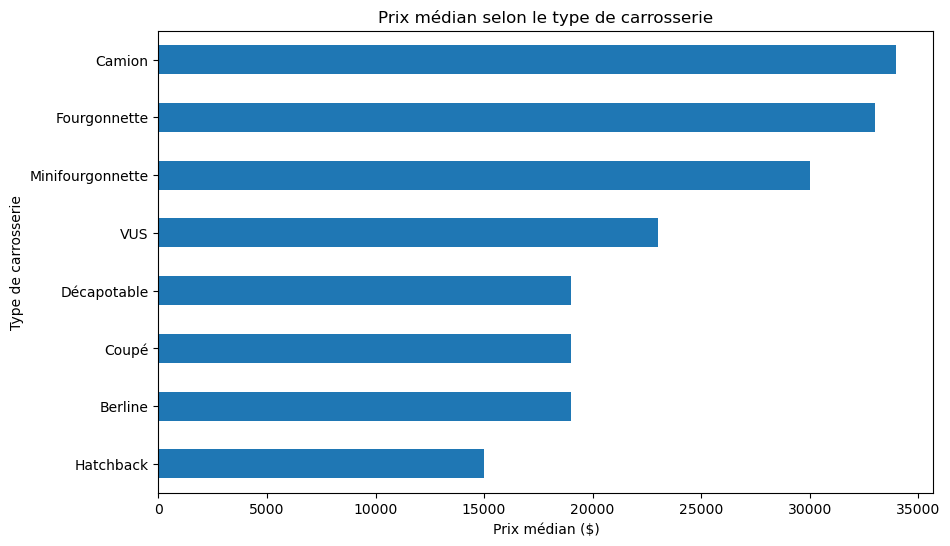

In [349]:
prix_median_carrosserie = (
    df_model.groupby("BODYDESCF")["PRICE"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 6))

prix_median_carrosserie.plot(kind="barh")

plt.title("Prix médian selon le type de carrosserie")
plt.xlabel("Prix médian ($)")
plt.ylabel("Type de carrosserie")

plt.show()

### Interprétation du prix selon le type de carrosserie

Le prix médian varie sensiblement selon le type de carrosserie.

Les camions, fourgonnettes et minifourgonnettes présentent les prix médians les plus élevés dans ce jeu de données, tandis que les hatchbacks affichent les prix médians les plus faibles.

Cela confirme que `BODYDESCF` apporte une information pertinente pour la prédiction du prix.

Ces écarts doivent toutefois être interprétés conjointement avec d'autres caractéristiques comme l'année, le kilométrage, la marque et le modèle.

### Corrélation entre les variables numériques

La matrice de corrélation permet d'observer les relations linéaires entre les variables numériques retenues et notamment leur relation avec la variable cible `PRICE`.

In [350]:
correlation = df_model[
    ["YEAR", "KM", "BODYDOORS", "PASSENGERS", "PRICE"]
].corr()

correlation

,YEAR,KM,BODYDOORS,PASSENGERS,PRICE
YEAR,1.000000,-0.445703,0.118929,0.156807,0.552095
KM,-0.445703,1.000000,-0.013959,0.095950,-0.302252
BODYDOORS,0.118929,-0.013959,1.000000,0.203917,-0.054424
PASSENGERS,0.156807,0.095950,0.203917,1.000000,0.242224
PRICE,0.552095,-0.302252,-0.054424,0.242224,1.000000


### Interprétation des corrélations

Parmi les variables numériques, `YEAR` présente la relation linéaire la plus importante avec `PRICE`, avec une corrélation d'environ 0,55. Les véhicules plus récents ont donc généralement tendance à avoir un prix plus élevé.

Le kilométrage (`KM`) présente une corrélation négative d'environ -0,30 avec le prix. Cela confirme que les véhicules plus kilométrés ont globalement tendance à être moins chers.

`PASSENGERS` présente une corrélation positive plus faible avec le prix, d'environ 0,24.

`BODYDOORS` présente une corrélation très faible avec `PRICE`, ce qui indique que le nombre de portes apporte peu d'information lorsqu'il est considéré seul.

On observe également une corrélation négative d'environ -0,45 entre `YEAR` et `KM`, ce qui est cohérent puisque les véhicules plus récents ont généralement parcouru moins de kilomètres.

Ces résultats montrent qu'aucune variable numérique ne permet à elle seule d'expliquer le prix. Les variables catégorielles comme la marque, le modèle et le type de carrosserie restent donc importantes pour la modélisation.

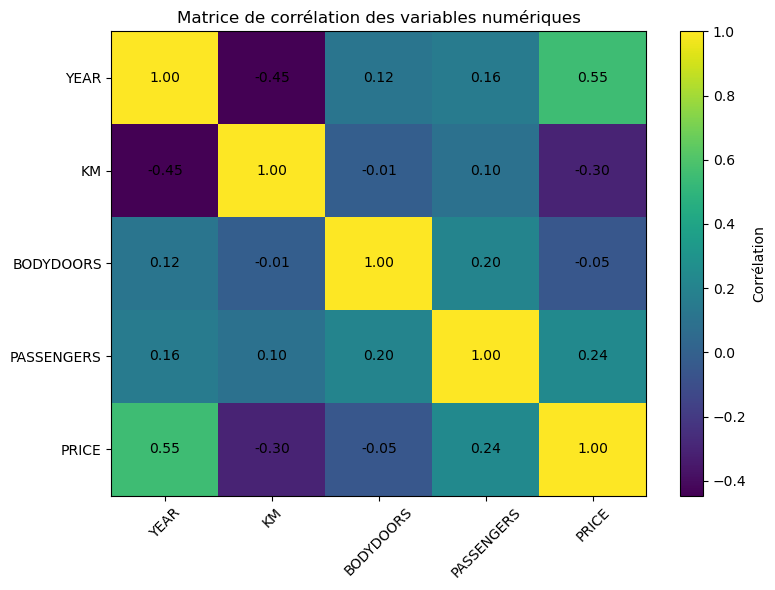

In [351]:
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation,
    aspect="auto"
)

plt.colorbar(label="Corrélation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.index)),
    correlation.index
)

for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Matrice de corrélation des variables numériques")

plt.tight_layout()
plt.show()

### Analyse de la variable MODEL

La variable `MODEL` contient le modèle commercial du véhicule.

Comme cette variable est catégorielle, il est important de vérifier combien de modèles différents sont présents dans le jeu de données et si certains modèles sont très peu représentés.

In [352]:
print("Nombre de modèles différents :", df_model["MODEL"].nunique())

df_model["MODEL"].value_counts().head(20)

Nombre de modèles différents : 218


MODEL
Kona              64
Sentra            53
Rogue             53
Elantra           51
1500 Classic      43
Kicks             43
Sportage          37
Escape            35
Seltos            33
Tiguan            32
Corolla           32
Qashqai           31
Sorento           30
Tucson            29
CX-5              28
Silverado 1500    25
Micra             24
Outlander         24
Santa Fe          23
Taos              22
Name: count, dtype: int64

### Répartition des modèles peu représentés

La variable `MODEL` possède une forte cardinalité avec 164 modèles différents.

On vérifie maintenant combien de modèles apparaissent seulement quelques fois dans le jeu de données. Cette information est importante puisque les modèles rares peuvent créer un grand nombre de colonnes lors de l'encodage catégoriel.

In [353]:
frequence_modeles = df_model["MODEL"].value_counts()

print("Modèles présents 1 seule fois :", (frequence_modeles == 1).sum())
print("Modèles présents 2 fois ou moins :", (frequence_modeles <= 2).sum())
print("Modèles présents 5 fois ou moins :", (frequence_modeles <= 5).sum())
print("Modèles présents plus de 5 fois :", (frequence_modeles > 5).sum())

Modèles présents 1 seule fois : 73
Modèles présents 2 fois ou moins : 99
Modèles présents 5 fois ou moins : 153
Modèles présents plus de 5 fois : 65


In [354]:
modeles_rares = frequence_modeles[frequence_modeles <= 5].index

nb_vehicules_modeles_rares = (
    df_model["MODEL"]
    .isin(modeles_rares)
    .sum()
)

print(
    "Nombre de véhicules appartenant à un modèle présent 5 fois ou moins :",
    nb_vehicules_modeles_rares
)

print(
    "Proportion du dataset :",
    round(nb_vehicules_modeles_rares / len(df_model) * 100, 1),
    "%"
)

Nombre de véhicules appartenant à un modèle présent 5 fois ou moins : 339
Proportion du dataset : 20.4 %


### Interprétation de la variable MODEL

La variable `MODEL` contient 218 catégories différentes, ce qui représente une forte cardinalité.

Parmi celles-ci, 153 modèles apparaissent cinq fois ou moins. Cependant, ces modèles représentent ensemble 339 véhicules, soit environ 20,4 % du jeu de données.

Cette proportion étant importante, les modèles rares ne sont pas regroupés à cette étape afin de conserver l'information potentiellement utile à la prédiction du prix.

Une variante regroupant les modèles rares pourra être testée lors de la phase de modélisation afin de mesurer objectivement son effet sur les performances et la capacité de généralisation des modèles.

In [355]:
df_model["PASSENGERS"].value_counts().sort_index()

PASSENGERS
0       4
2       9
3       1
4      52
5    1381
6      96
7     101
8      16
Name: count, dtype: int64

In [356]:
df_model[df_model["PASSENGERS"] == 0][
    ["YEAR", "MAKE", "MODEL", "BODYDESCF", "PASSENGERS", "PRICE"]
]

,YEAR,MAKE,MODEL,BODYDESCF,PASSENGERS,PRICE
150,2023,GMC,Savana Cargo,Fourgonnette,0,32995
156,2019,Chevrolet,Express Commercial Cutaway,Berline,0,26995
163,2026,GMC,Sierra 2500 HD,Berline,0,119900
795,2019,Ford,Transit Cutaway,Minifourgonnette,0,27995


### Vérification des valeurs inhabituelles

La variable `PASSENGERS` contient une observation avec la valeur 0.  
Cette observation correspond à un Chevrolet Express Commercial Cutaway 2019, un véhicule commercial. La valeur est donc conservée.

In [357]:
df_model["PRICE"].describe()

count      1660.000000
mean      23455.788554
std        8088.072083
min        6995.000000
25%       17995.000000
50%       21995.000000
75%       27495.000000
max      119900.000000
Name: PRICE, dtype: float64

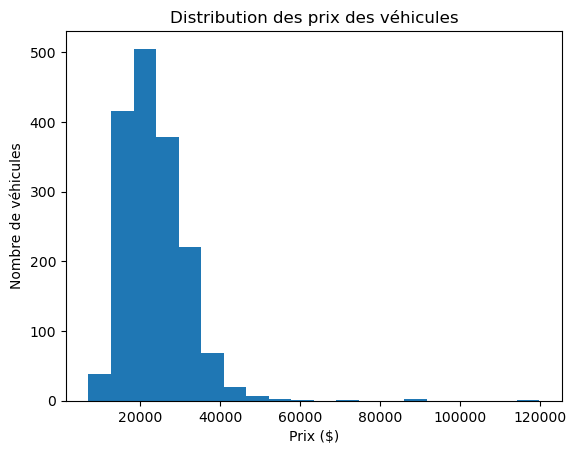

In [358]:
plt.hist(df_model["PRICE"], bins=20)

plt.xlabel("Prix ($)")
plt.ylabel("Nombre de véhicules")
plt.title("Distribution des prix des véhicules")

plt.show()

In [359]:
df_model.sort_values("PRICE", ascending=False).head(10)[
    ["YEAR", "MAKE", "MODEL", "KM", "PRICE"]
]

,YEAR,MAKE,MODEL,KM,PRICE
163,2026,GMC,Sierra 2500 HD,7500,119900
951,2020,Porsche,Taycan,35000,89999
1274,2024,Chevrolet,Silverado 2500 HD,23892,89995
604,2026,Cadillac,VISTIQ,11127,88995
381,2024,RAM,2500,42150,69995
1551,2024,Jeep,Wagoneer S,10361,59995
1013,2025,Chevrolet,Express Commercial Cutaway,35870,54995
974,2024,Ford,F-150 Lightning,88500,53995
1376,2024,GMC,Canyon,47135,49995
1402,2022,Chevrolet,Silverado 2500 HD,77080,49995


### Vérification des prix élevés

La distribution des prix présente une asymétrie vers les valeurs élevées.

Le véhicule le plus cher du jeu de données est un GMC Sierra 2500 HD 2026 affiché à 119 900 $. Parmi les autres véhicules les plus chers figurent notamment un Porsche Taycan, un Chevrolet Silverado 2500 HD et un Cadillac VISTIQ.

Ces valeurs sont cohérentes avec les modèles concernés et ne sont donc pas considérées comme des anomalies.

Les véhicules à prix élevé sont conservés afin de préserver la diversité du jeu de données et permettre aux modèles d'apprendre également sur cette partie du marché.

In [360]:
df_model[variables_categorielles].nunique().sort_values(ascending=False)

MODEL         218
MAKE           33
COLORF         21
BODYDESCF       8
FUEL            7
DRIVETRAIN      6
TRANSDESCF      2
dtype: int64

In [362]:
df_model.to_csv(
    "../data/interim/vehicles_clean.csv",
    index=False
)

print("Fichier sauvegardé dans data/interim/vehicles_clean.csv")

Fichier sauvegardé dans data/interim/vehicles_clean.csv


## Conclusion de la préparation des données

Le jeu de données consolidé contient 1 660 véhicules et 106 variables brutes.

Pour la modélisation, 11 variables explicatives ont été retenues ainsi que la variable cible `PRICE`, ce qui donne un jeu de données préparé de 1 660 observations et 12 colonnes.

Les principales étapes de préparation ont permis de :

- éliminer les doublons en utilisant `ID` comme clé unique ;
- conserver la version la plus récente lorsqu'un même véhicule apparaissait plusieurs fois ;
- traiter les quelques valeurs manquantes de `FUEL` et `DRIVETRAIN` avec la catégorie `Inconnu` ;
- corriger les valeurs `BODYDOORS = 0` et `PASSENGERS = 0` en utilisant la médiane des valeurs valides ;
- vérifier les valeurs extrêmes de kilométrage et de prix sans supprimer les observations jugées plausibles.

L'analyse exploratoire montre notamment que :

- la distribution de `PRICE` est asymétrique vers les prix élevés ;
- `YEAR` présente la relation numérique la plus forte avec `PRICE` ;
- `KM` présente une relation négative avec `PRICE` ;
- les prix médians diffèrent selon la marque et le type de carrosserie ;
- la variable `MODEL` possède une forte cardinalité avec 218 modèles différents ;
- les modèles apparaissant cinq fois ou moins représentent environ 20,4 % du jeu de données et sont donc conservés.

Le jeu de données préparé est sauvegardé dans `data/interim/vehicles_clean.csv` et peut maintenant être utilisé pour la phase de modélisation.